# Визуализация, Matplotlib

В этом практикуме: базовые диаграммы, распределения, связи признаков,
временные ряды, компоновка нескольких графиков и визуализация с **Seaborn**.
Запускайте ячейки сверху вниз. Данные и случайные примеры воспроизводимы.

Если библиотек нет, выполните следующую ячейку, убрав `#` перед `%pip`,
затем при необходимости перезапустите ядро.

In [2]:
!pip3 install numpy pandas matplotlib seaborn


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [8]:
import numpy as np
import pandas as pd

In [5]:
import matplotlib.pyplot as plt

In [9]:
from pathlib import Path

data_path = Path('loan_data.csv')
if data_path.exists():
    df = pd.read_csv(data_path)
    print('Загружен loan_data.csv')
else:
    # Это синтетические учебные данные, а не сведения о реальных заёмщиках.
    rng = np.random.default_rng(42)
    n = 300
    income = rng.lognormal(mean=8.4, sigma=0.45, size=n)
    df = pd.DataFrame({
        'Dependents': rng.choice(['0', '1', '2', '3+'], n),
        'ApplicantIncome': income.round().astype(int),
        'LoanAmount': np.clip(income / 45 + rng.normal(35, 25, n), 15, None).round(1),
    })
    print('loan_data.csv не найден: используются синтетические учебные данные.')

loan_data.csv не найден: используются синтетические учебные данные.


In [6]:
df.head()

,Dependents,ApplicantIncome,LoanAmount
0,2,5101,181.4
1,0,2785,88.3
2,1,6234,136.6
3,1,6790,212.6
4,2,1848,67.8


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Dependents       300 non-null    str    
 1   ApplicantIncome  300 non-null    int64  
 2   LoanAmount       300 non-null    float64
dtypes: float64(1), int64(1), str(1)
memory usage: 7.2 KB


# Визуализация данных

Правила хорошей визуализации:
* понятна любому человеку, а не только вам
* исчерпывающая, т.е. не оставляет открытых вопросов после изучения
* наталкивает на полезные мысли и выводы

#### Pie plot

Плюсы:

* простой и понятный график
* ясно демонстрирует пропорции частей целого

Минусы:

* плохо подходит для сравнения большого количества долей
* не работает с отрицательными значениями

In [11]:
dependent_counts = df['Dependents'].astype('string').fillna('Не указано').value_counts()
pie_vals_dependents = [
    (str(category), round(count / dependent_counts.sum() * 100, 2))
    for category, count in dependent_counts.items()
]

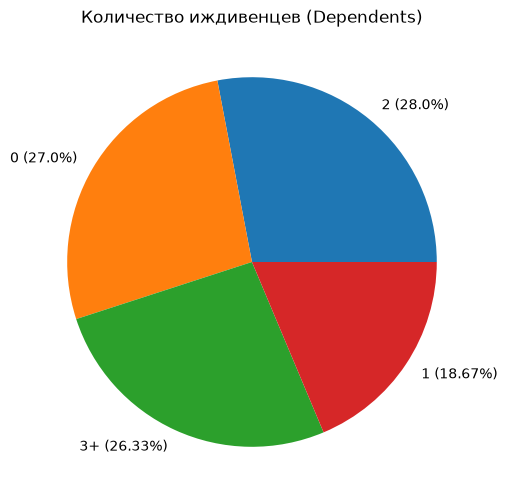

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(dependent_counts, labels=[f'{name} ({share}%)' for name, share in pie_vals_dependents])
ax.set_title('Количество иждивенцев (Dependents)')
plt.show()

### Bar plot

Сохраняет преимущества pie plot, при этом решает его проблемы и добавляет ясности в график, однако при большом количестве категорий график будет перегружен.

Bar plot - для категориальных*, аналог для непрерывных величин - Hist plot.

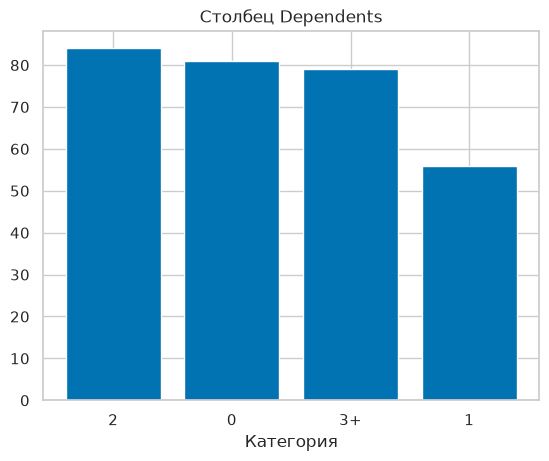

In [12]:
plt.bar(df['Dependents'].value_counts().index, df['Dependents'].value_counts().values, )
plt.title('Столбец Dependents')
plt.xlabel('Категория')
plt.show()

#### Box plot

Ящик с усами :)


Плюсы:
* показывает оценку распределения
* показывает выбросы

Минусы:
* точно не для категориальных признаков
* когда нужно проверить много данных – вручную сложно и долго

In [13]:
loan_amount = df['LoanAmount'].dropna()  # Не изменяем исходный DataFrame.

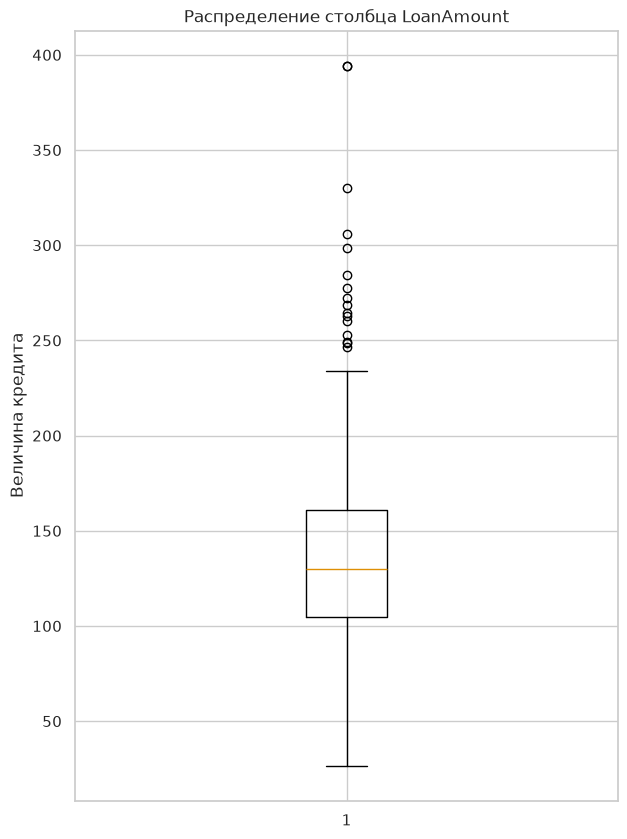

In [14]:
plt.figure(figsize=(7, 10))
plt.boxplot(loan_amount)
plt.title('Распределение столбца LoanAmount')
plt.ylabel('Величина кредита')
plt.show()

### Scatter plot: связь двух признаков

Каждая точка — одно наблюдение. Прозрачность помогает увидеть наложения. Связь на графике сама по себе не доказывает причинность.

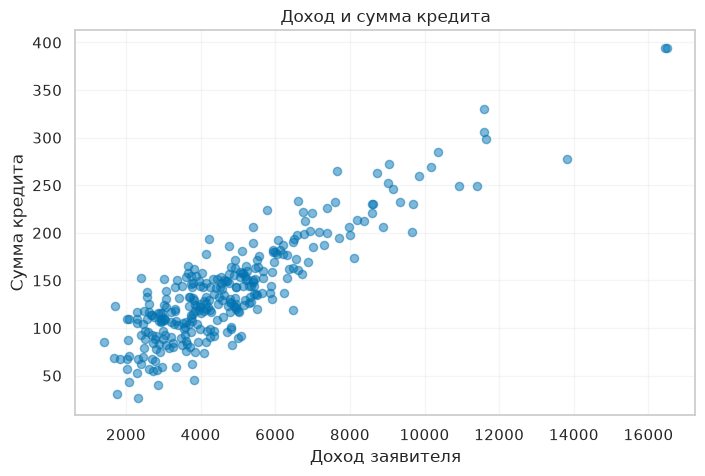

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['ApplicantIncome'], df['LoanAmount'], alpha=0.5, s=35)
ax.set(title='Доход и сумма кредита', xlabel='Доход заявителя', ylabel='Сумма кредита')
ax.grid(alpha=0.2)
plt.show()

## Дополнительные примеры Matplotlib

Далее используем отдельный синтетический набор о продажах. Он не зависит от
состава `loan_data.csv`. Доход и выручка здесь выражены в условных единицах.
В интерфейсе `fig, ax = plt.subplots()` объект `fig` — вся фигура,
а `ax` — область построения. Подписи и настройки задаём через `ax`.

In [16]:
rng = np.random.default_rng(7)
dates = pd.date_range('2025-01-01', periods=90, freq='D')
daily = pd.DataFrame({
    'Дата': dates,
    'Онлайн': np.maximum(0, 100 + np.arange(90) * 0.8 + rng.normal(0, 12, 90)),
    'Магазин': np.maximum(0, 85 + np.arange(90) * 0.4 + rng.normal(0, 10, 90)),
}).set_index('Дата')
n = 240
channel = rng.choice(['Онлайн', 'Магазин', 'Партнёры'], n)
budget = rng.uniform(10, 100, n)
sales = pd.DataFrame({
    'Канал': channel,
    'Регион': rng.choice(['Север', 'Юг', 'Центр'], n),
    'Бюджет': budget,
    'Выручка': np.maximum(0, 30 + 2.5 * budget + (channel == 'Онлайн') * 35 + rng.normal(0, 30, n)),
    'Оценка': rng.integers(1, 6, n),
})
channels = ['Онлайн', 'Магазин', 'Партнёры']
sales.head()

,Канал,Регион,Бюджет,Выручка,Оценка
0,Партнёры,Центр,78.192160,198.130445,2
1,Магазин,Центр,74.916569,191.667360,1
2,Партнёры,Юг,50.031912,161.219677,1
3,Партнёры,Центр,44.036230,119.020610,1
4,Онлайн,Север,47.779384,204.711992,2


### Line graph: динамика и скользящее среднее

Линия подходит для упорядоченной оси времени. Среднее за 7 дней сглаживает ежедневный шум; первые 6 значений среднего отсутствуют.

gfdkgjdlfkjg 
# hgkjfdhgkjdfg

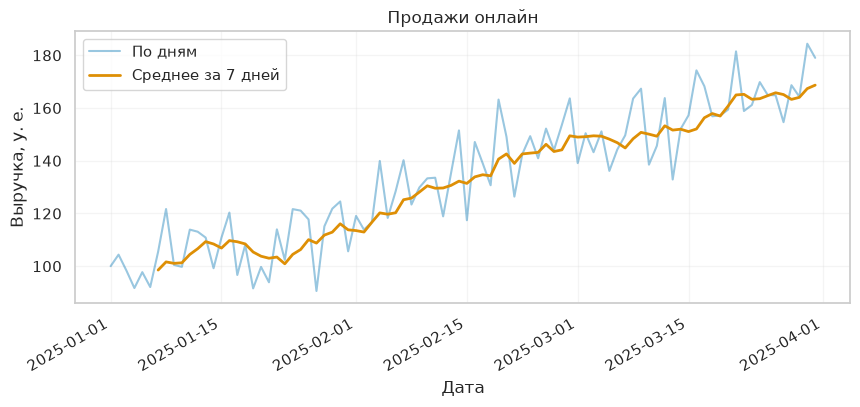

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily['Онлайн'], alpha=0.4, label='По дням')
ax.plot(daily.index, daily['Онлайн'].rolling(7).mean(), linewidth=2, label='Среднее за 7 дней')
ax.set(title='Продажи онлайн', xlabel='Дата', ylabel='Выручка, у. е.')
ax.legend()
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

### Histogram: распределение числового признака

В отличие от bar plot, гистограмма группирует числа в интервалы. Число интервалов bins влияет на вид распределения.

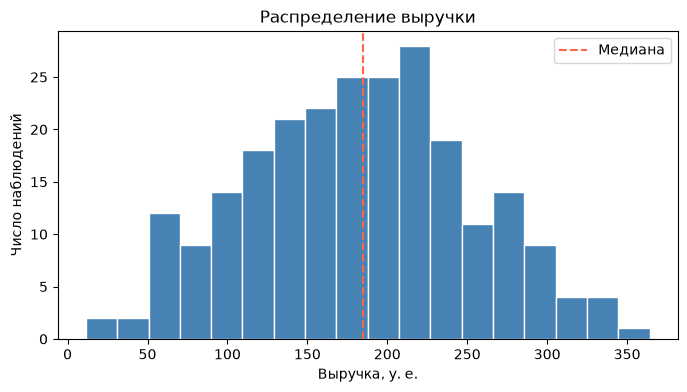

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sales['Выручка'], bins=18, color='steelblue', edgecolor='white')
ax.hline(sales['Выручка'].median(), color='tomato', linestyle='--', label='Медиана')
ax.set(title='Распределение выручки', xlabel='Выручка, у. е.', ylabel='Число наблюдений')
ax.legend()
plt.show()

### Горизонтальная столбчатая диаграмма

Удобна для длинных названий. Сортировка помогает сравнивать категории; числовые подписи показывают точные значения.

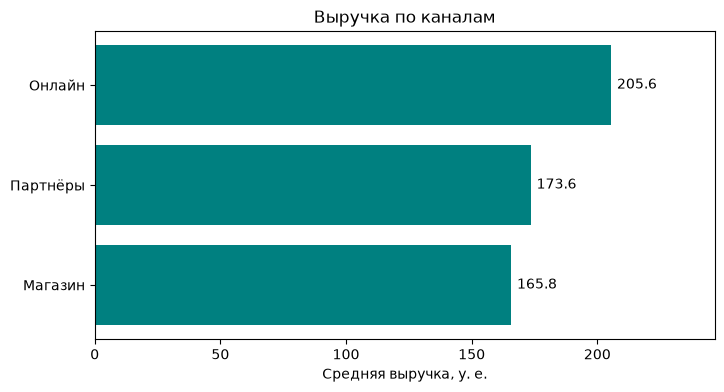

In [16]:
means = sales.groupby('Канал')['Выручка'].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(means.index, means.values, color='teal')
ax.bar_label(bars, fmt='%.1f', padding=4)
ax.set(xlabel='Средняя выручка, у. е.', title='Выручка по каналам')
ax.set_xlim(0, means.max() * 1.2)
plt.show()

### Группированные столбцы

Сравниваем каналы внутри каждого региона. Сводная таблица содержит средние значения.

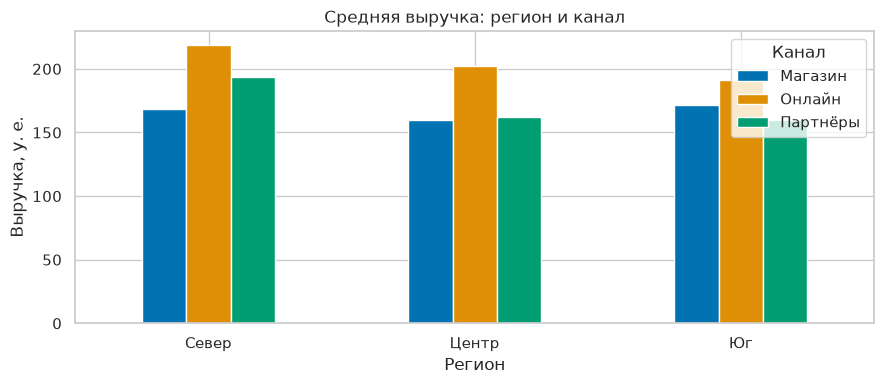

In [18]:
summary = sales.pivot_table(index='Регион', columns='Канал', values='Выручка', aggfunc='mean')
fig, ax = plt.subplots(figsize=(9, 4))
summary.plot.bar(ax=ax, rot=0)
ax.set(title='Средняя выручка: регион и канал', ylabel='Выручка, у. е.')
ax.legend(title='Канал')
plt.tight_layout()
plt.show()

### Столбцы с накоплением: доли каналов

Каждый столбец нормирован до 100%. Показываем доли наблюдений, а не доли выручки.

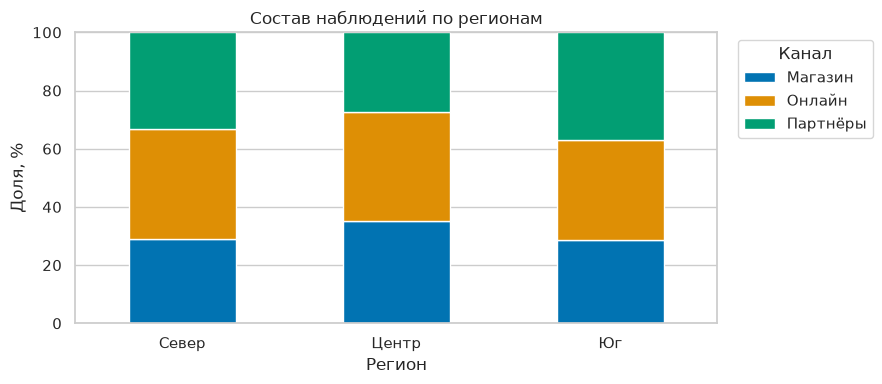

In [19]:
shares = pd.crosstab(sales['Регион'], sales['Канал'], normalize='index') * 100
fig, ax = plt.subplots(figsize=(9, 4))
shares.plot.bar(stacked=True, ax=ax, rot=0)
ax.set(title='Состав наблюдений по регионам', ylabel='Доля, %', ylim=(0, 100))
ax.legend(title='Канал', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Error bars: среднее и разброс

Усы ниже показывают ± одно стандартное отклонение наблюдений. Это не доверительный интервал среднего.

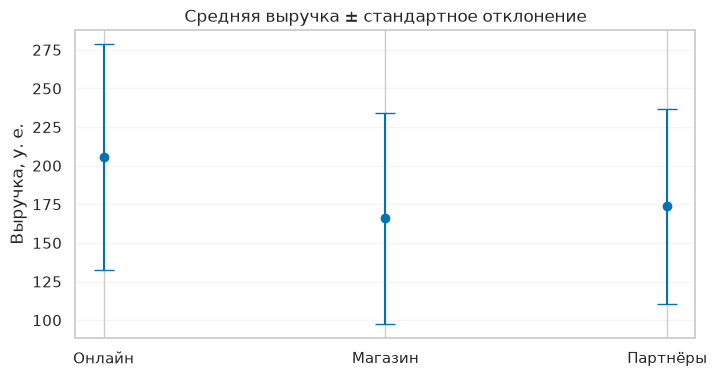

In [20]:
stats = sales.groupby('Канал')['Выручка'].agg(['mean', 'std']).reindex(channels)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(stats.index, stats['mean'], yerr=stats['std'], fmt='o', capsize=7)
ax.set(title='Средняя выручка ± стандартное отклонение', ylabel='Выручка, у. е.')
ax.grid(axis='y', alpha=0.2)
plt.show()

### Области с накоплением

Показывают общий объём и вклад каждого ряда во времени. Для сравнения отдельных рядов удобнее обычные линии.

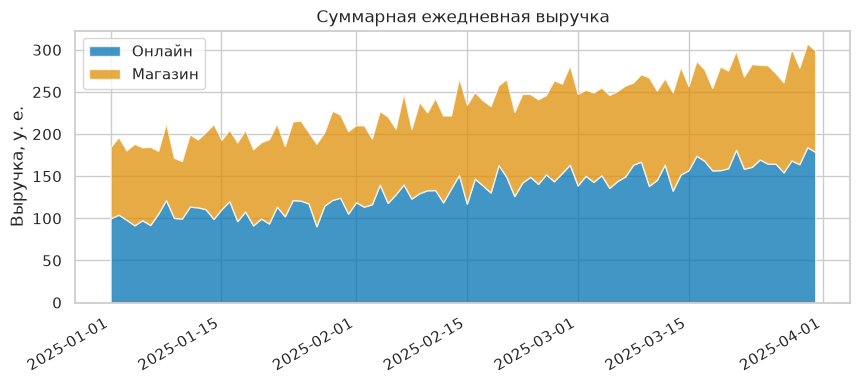

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(daily.index, daily['Онлайн'], daily['Магазин'], labels=['Онлайн', 'Магазин'], alpha=0.75)
ax.set(title='Суммарная ежедневная выручка', ylabel='Выручка, у. е.')
ax.legend(loc='upper left')
fig.autofmt_xdate()
plt.show()

### Subplots: несколько графиков на одной фигуре

Сопоставляем распределение и связь признаков. Аннотация отмечает наблюдение с максимальной выручкой.

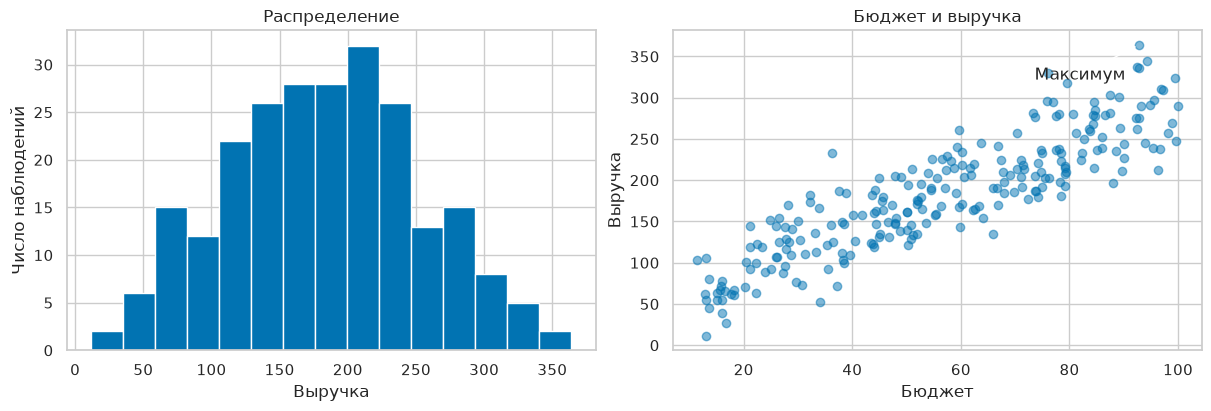

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
axes[0].hist(sales['Выручка'], bins=15, edgecolor='white')
axes[0].set(title='Распределение', xlabel='Выручка', ylabel='Число наблюдений')
axes[1].scatter(sales['Бюджет'], sales['Выручка'], alpha=0.5)
peak = sales.loc[sales['Выручка'].idxmax()]
axes[1].annotate('Максимум', xy=(peak['Бюджет'], peak['Выручка']),
                 xytext=(-75, -25), textcoords='offset points',
                 arrowprops={'arrowstyle': '->'})
axes[1].set(title='Бюджет и выручка', xlabel='Бюджет', ylabel='Выручка')
plt.show()

### Hexbin: плотность большого облака точек

Когда точки перекрываются, hexbin объединяет их в шестиугольные ячейки. Цвет показывает число наблюдений.

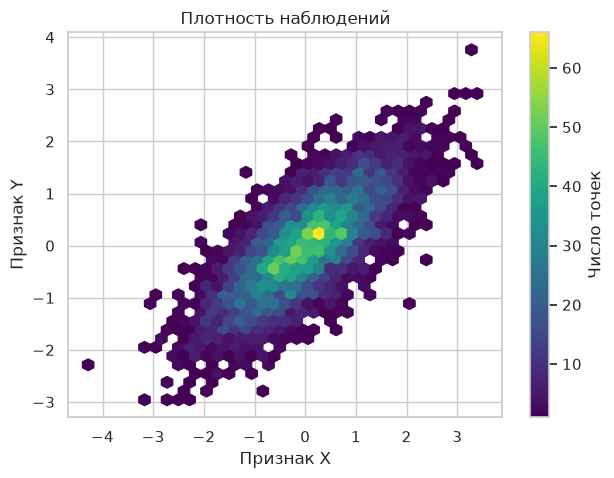

In [23]:
dense_rng = np.random.default_rng(21)
x_dense = dense_rng.normal(size=5000)
y_dense = 0.7 * x_dense + dense_rng.normal(scale=0.6, size=5000)
fig, ax = plt.subplots(figsize=(7, 5))
density = ax.hexbin(x_dense, y_dense, gridsize=35, mincnt=1, cmap='viridis')
fig.colorbar(density, ax=ax, label='Число точек')
ax.set(title='Плотность наблюдений', xlabel='Признак X', ylabel='Признак Y')
plt.show()

## Примеры с Seaborn

Seaborn работает поверх Matplotlib и удобно строит статистические графики из
DataFrame: `data` задаёт таблицу, `x` и `y` — имена столбцов,
`hue` — группировку цветом. Здесь используем уже созданную таблицу `sales`:
скачивать встроенные датасеты не нужно.

Функции `histplot`, `scatterplot`, `boxplot` принимают `ax`.
`pairplot`, `relplot` и `catplot` создают собственную фигуру и возвращают
объект сетки, у которого есть атрибут `fig`.

In [24]:
import seaborn as sns

sns.set_theme(style='whitegrid', palette='colorblind')

### Seaborn histplot и KDE

Гистограмма показывает частоты, а KDE — сглаженную оценку распределения. Форма KDE зависит от сглаживания; она может выходить за границы допустимых значений.

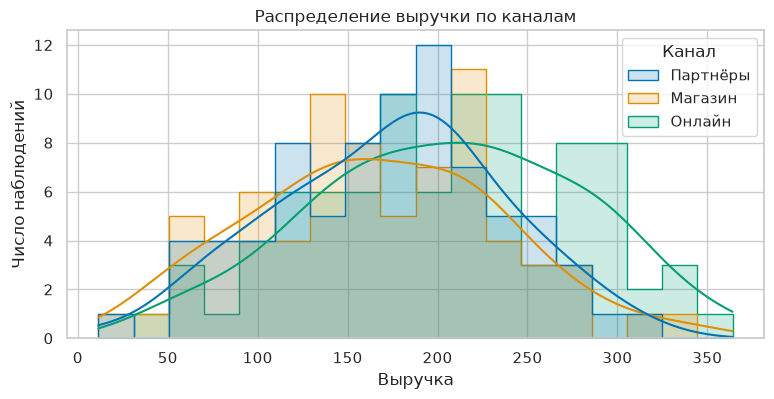

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=sales, x='Выручка', hue='Канал', bins=18, kde=True,
             element='step', alpha=0.2, ax=ax)
ax.set(title='Распределение выручки по каналам', ylabel='Число наблюдений')
plt.show()

### Seaborn ECDF: накопленная доля

Высота кривой — доля наблюдений со значением не больше x. ECDF не требует выбора интервалов или сглаживания.

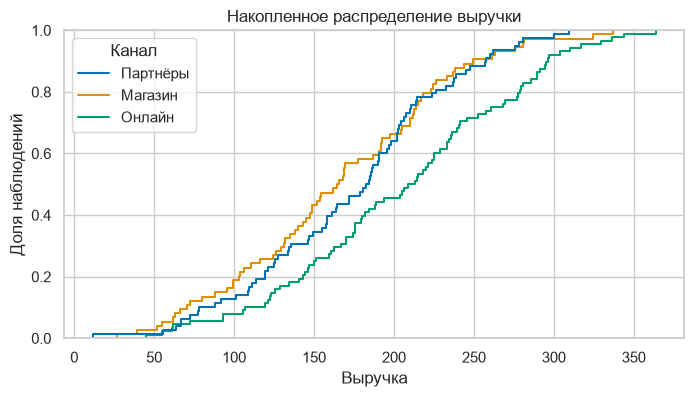

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.ecdfplot(data=sales, x='Выручка', hue='Канал', ax=ax)
ax.set(title='Накопленное распределение выручки', ylabel='Доля наблюдений')
plt.show()

### Seaborn boxplot и отдельные наблюдения

Ящик показывает квартильный диапазон и медиану. Усы обычно ограничены 1,5 межквартильного размаха; точки за усами не обязательно ошибки.

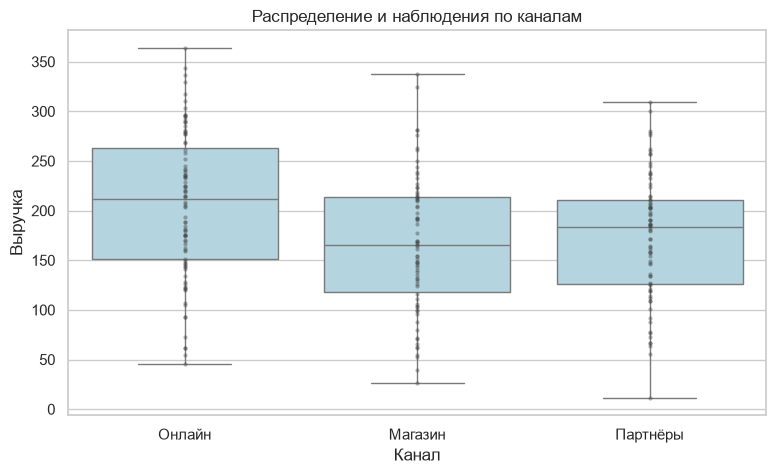

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=sales, x='Канал', y='Выручка', order=channels,
            color='lightblue', showfliers=False, ax=ax)
sns.stripplot(data=sales, x='Канал', y='Выручка', order=channels,
              color='0.25', alpha=0.4, jitter=False, size=3, ax=ax)
ax.set_title('Распределение и наблюдения по каналам')
plt.show()

### Seaborn violinplot

Ширина «скрипки» отражает оценку плотности, внутренние линии — квартили. cut=0 ограничивает рисунок наблюдаемым диапазоном.

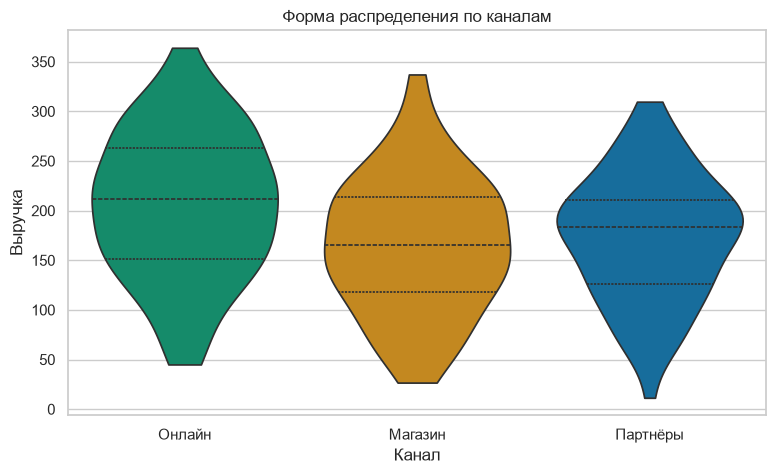

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=sales, x='Канал', y='Выручка', hue='Канал', order=channels,
               inner='quart', cut=0, legend=False, ax=ax)
ax.set_title('Форма распределения по каналам')
plt.show()

### Seaborn scatterplot: цвет и форма

Цвет кодирует канал, форма маркера — регион. Избегайте слишком большого числа категорий в одной легенде.

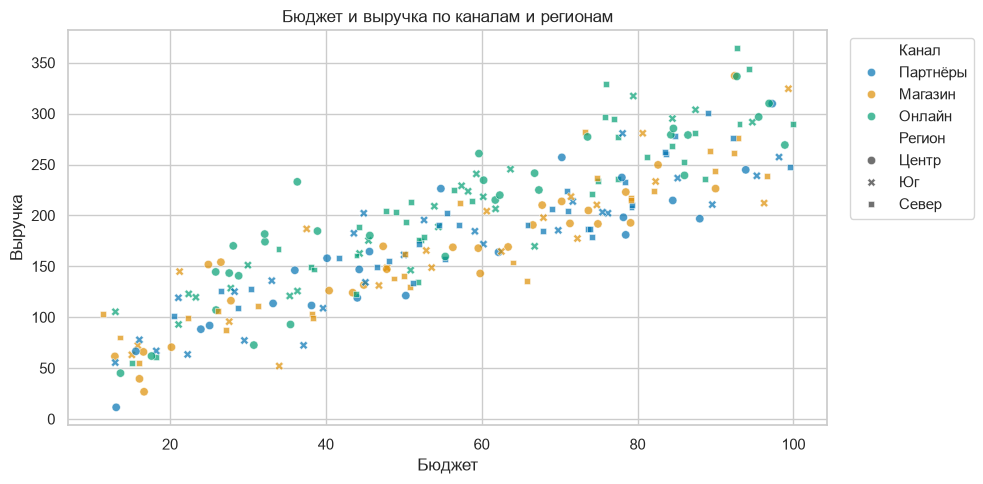

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=sales, x='Бюджет', y='Выручка', hue='Канал',
                style='Регион', alpha=0.7, ax=ax)
ax.set_title('Бюджет и выручка по каналам и регионам')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Seaborn regplot: линейный тренд

Линия — линейная регрессия, полоса — 95%-й bootstrap-интервал оценки линии. Это не интервал для отдельных будущих наблюдений и не доказательство причинности.

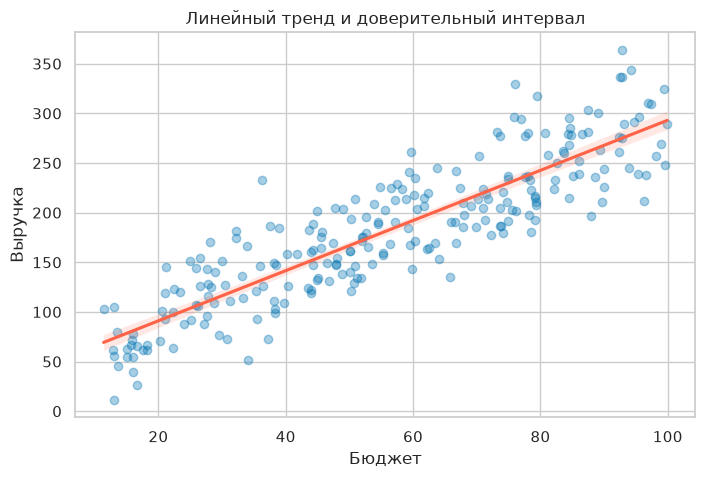

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=sales, x='Бюджет', y='Выручка', ci=95, seed=42,
             scatter_kws={'alpha': 0.35}, line_kws={'color': 'tomato'}, ax=ax)
ax.set_title('Линейный тренд и доверительный интервал')
plt.show()

### Seaborn barplot и countplot

barplot агрегирует числовой признак (по умолчанию среднее), countplot считает строки. Усы слева — 95%-й bootstrap-интервал среднего.

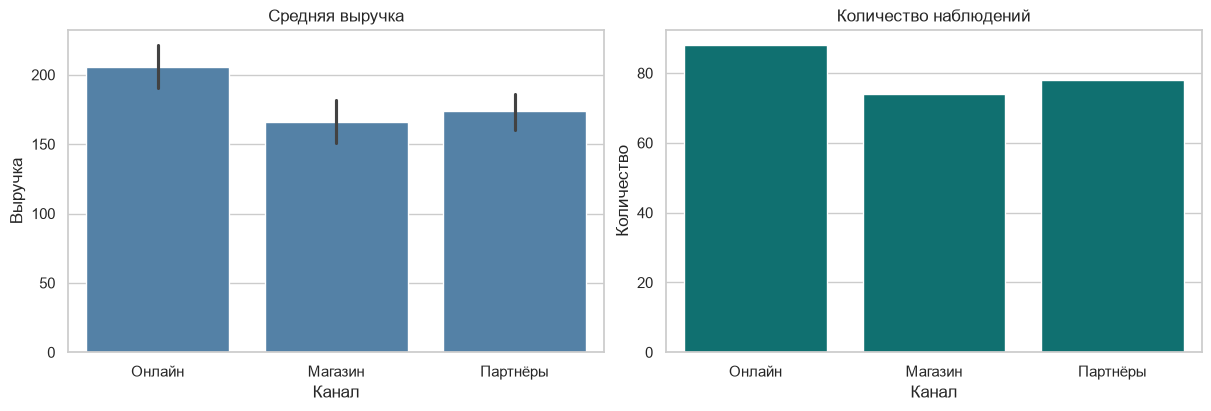

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
sns.barplot(data=sales, x='Канал', y='Выручка', order=channels,
             errorbar=('ci', 95), seed=42, color='steelblue', ax=axes[0])
sns.countplot(data=sales, x='Канал', order=channels, color='teal', ax=axes[1])
axes[0].set_title('Средняя выручка')
axes[1].set(title='Количество наблюдений', ylabel='Количество')
plt.show()

### Seaborn heatmap: корреляции

Корреляция Пирсона отражает линейную связь. Фиксируем шкалу от −1 до 1 и подписываем коэффициенты. Числовая оценка здесь используется как порядковая шкала с условно равными шагами.

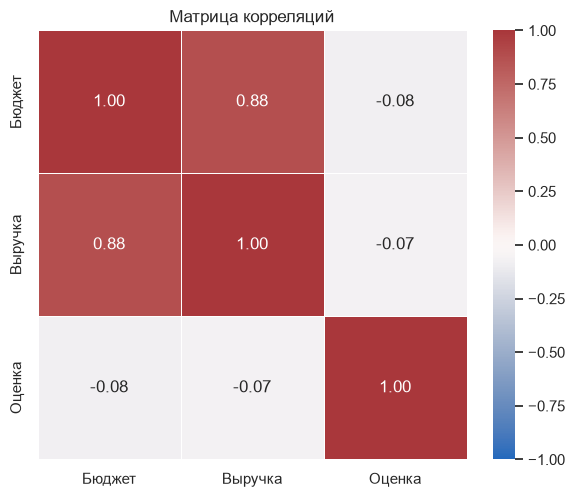

In [31]:
corr = sales[['Бюджет', 'Выручка', 'Оценка']].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1,
             center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title('Матрица корреляций')
plt.tight_layout()
plt.show()

### Seaborn heatmap: сводная таблица

Тепловая карта подходит не только для корреляций: цветом можно показать среднее значение на пересечении двух категорий.

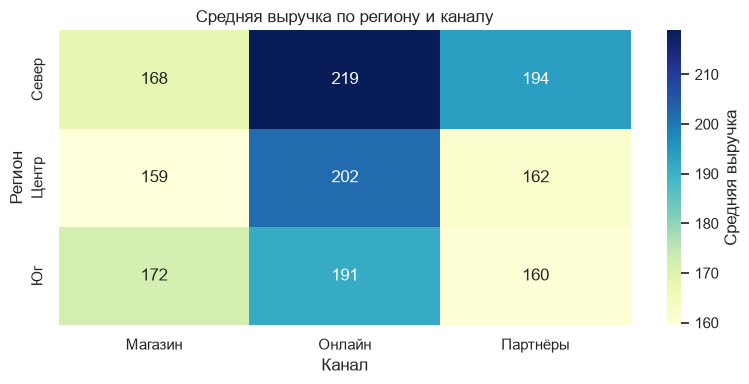

In [32]:
region_channel = sales.pivot_table(index='Регион', columns='Канал', values='Выручка', aggfunc='mean')
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(region_channel, annot=True, fmt='.0f', cmap='YlGnBu',
             cbar_kws={'label': 'Средняя выручка'}, ax=ax)
ax.set_title('Средняя выручка по региону и каналу')
plt.tight_layout()
plt.show()

### Seaborn pairplot: обзор связей

Попарные диаграммы быстро показывают связи и распределения. Выбирайте несколько признаков: число панелей растёт квадратично.

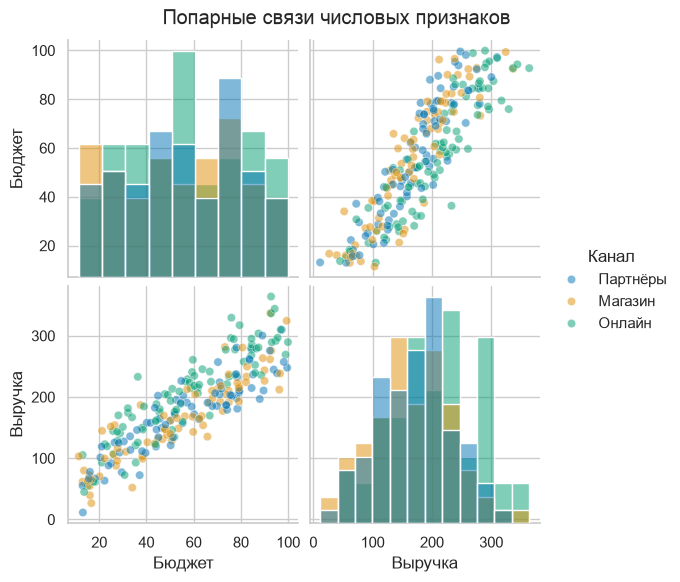

In [33]:
g = sns.pairplot(sales, vars=['Бюджет', 'Выручка'], hue='Канал',
                 diag_kind='hist', plot_kws={'alpha': 0.5}, height=2.8)
g.fig.suptitle('Попарные связи числовых признаков', y=1.03)
plt.show()

### Seaborn relplot: отдельная панель для каждого региона

Фасеты позволяют сравнивать группы на одинаковых шкалах. relplot создаёт всю сетку самостоятельно.

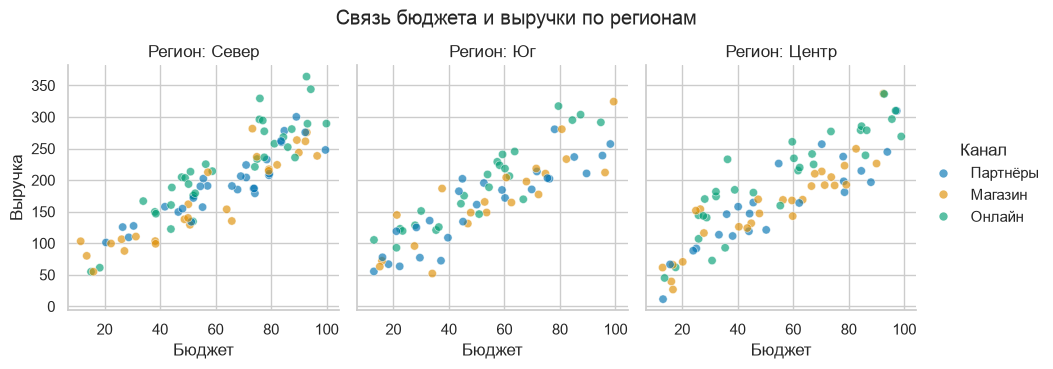

In [34]:
g = sns.relplot(data=sales, x='Бюджет', y='Выручка', hue='Канал',
                col='Регион', col_order=['Север', 'Юг', 'Центр'],
                kind='scatter', height=3.5, aspect=0.9, alpha=0.65)
g.set_titles('Регион: {col_name}')
g.fig.suptitle('Связь бюджета и выручки по регионам', y=1.05)
plt.show()

### Seaborn catplot: категории по панелям

Аналогичная сетка для категориальных графиков. kind выбирает тип диаграммы: box, violin, bar и другие.

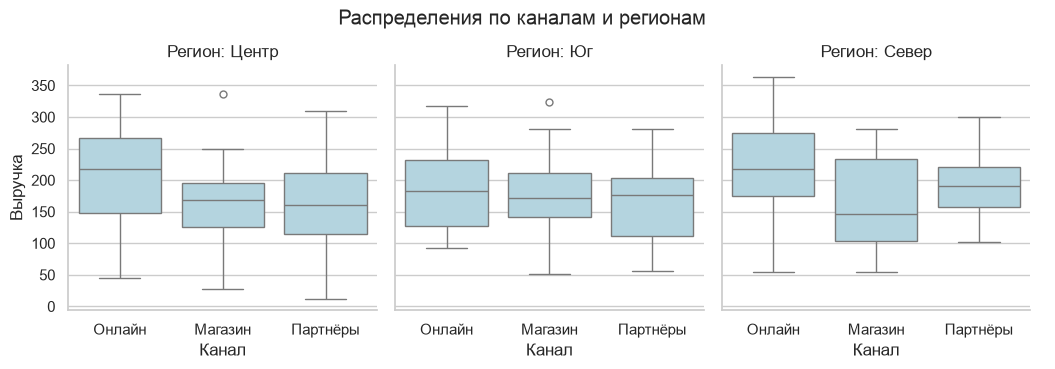

In [35]:
g = sns.catplot(data=sales, x='Канал', y='Выручка', col='Регион',
                order=channels, kind='box', color='lightblue', height=3.5, aspect=1)
g.set_titles('Регион: {col_name}')
g.fig.suptitle('Распределения по каналам и регионам', y=1.05)
plt.show()

## Как сохранять графики

`fig.savefig()` сохраняет конкретную фигуру: PNG подходит для вставки в документы,
SVG — для масштабируемой графики. Сохраняйте до `plt.show()`.
Для Seaborn-сеток используйте `g.fig.savefig(...)`.
Следующая ячейка создаёт папку `matplotlib_examples_output` в рабочем каталоге
и записывает PNG, SVG и двухстраничный PDF. Повторный запуск обновит эти файлы.

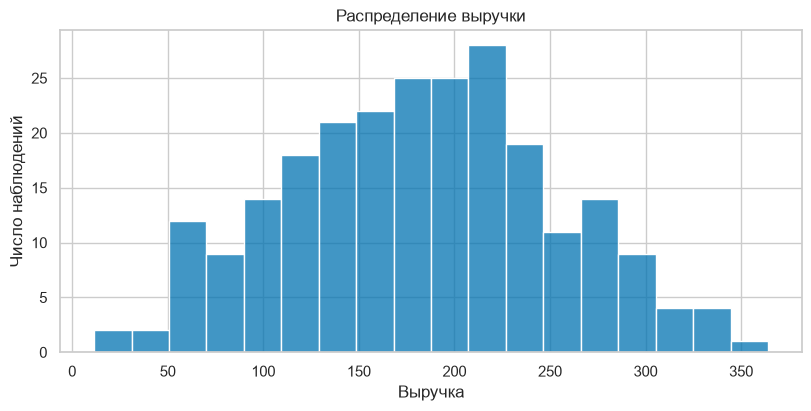

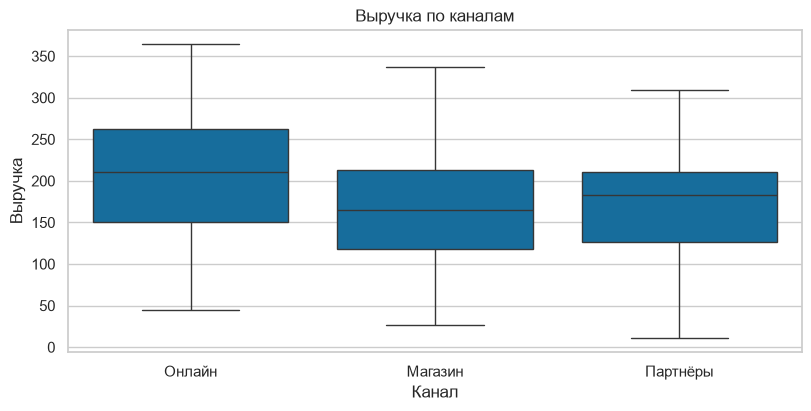

Графики сохранены в: /private/tmp/matplotlib-practice-run/matplotlib_examples_output


In [36]:
from matplotlib.backends.backend_pdf import PdfPages

output_dir = Path('matplotlib_examples_output')
output_dir.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
sns.histplot(data=sales, x='Выручка', bins=18, ax=ax)
ax.set(title='Распределение выручки', ylabel='Число наблюдений')
fig.savefig(output_dir / 'revenue_hist.png', dpi=180, bbox_inches='tight')
fig.savefig(output_dir / 'revenue_hist.svg', bbox_inches='tight')

# Контекстный менеджер закрывает PDF даже при ошибке внутри блока.
with PdfPages(output_dir / 'отчет.pdf') as pdf:
    pdf.savefig(fig, bbox_inches='tight')
    fig_second, ax_second = plt.subplots(figsize=(8, 4), layout='constrained')
    sns.boxplot(data=sales, x='Канал', y='Выручка', order=channels, ax=ax_second)
    ax_second.set_title('Выручка по каналам')
    pdf.savefig(fig_second, bbox_inches='tight')
plt.show()
print(f'Графики сохранены в: {output_dir.resolve()}')

## Задания для самостоятельной практики

1. Сравните гистограммы с `bins=5`, `20` и `50`. Какие детали появляются или исчезают?
2. В примере скользящего среднего измените окно с 7 на 14 дней.
3. В группированных столбцах замените среднее на медиану. Как изменится сравнение?
4. Постройте scatterplot только для региона «Север», выделив каналы цветом.
5. Соберите фигуру 2 × 2: гистограмма, boxplot, scatterplot и тепловая карта.
6. Сохраните одну из Seaborn-сеток в PNG через `g.fig.savefig()`.

## Как выбрать график

| Задача | Подходящие графики |
| --- | --- |
| Сравнить категории | bar, barh, countplot |
| Посмотреть распределение | hist, boxplot, violinplot, ECDF |
| Проверить связь числовых признаков | scatter, hexbin, regplot |
| Показать изменение во времени | line, area |
| Показать состав целого | stacked bar, pie для небольшого числа долей |
| Сравнить множество групп | subplots, relplot, catplot |
| Показать таблицу цветом | heatmap |

## Полезные ссылки

- [Галерея Matplotlib](https://matplotlib.org/stable/gallery/index.html)
- [Галерея Seaborn](https://seaborn.pydata.org/examples/index.html)
- [Учебник Seaborn](https://seaborn.pydata.org/tutorial.html)